# ID-Aware Blend Experiment

Experimental OOF-safe blend that adds a local row-ID prior derived from nearby training rows.

## Overview

- Builds an OOF-safe local target prior from nearby training IDs.
- Blends BERTweet, sparse, and ID-prior scores.
- Applies Bayesian smoothing to the local prior.
- Writes `id_aware_submission.csv` and `artifacts/id_aware_predictions.npz`.
- Includes diagnostics that make the ID prior contribution and caveats visible.

Source script: `id_aware_blend.py`


## Environment Setup

### Required Packages

Install the project dependencies from the repository root:

```bash
python3 -m venv .venv
.venv/bin/pip install -r requirements.txt
```

### Notebook Path

Run notebooks from the repository root when possible. If you open a notebook from `notebooks/`, the root-detection cell resolves the parent project directory automatically.

### Hardware Requirements

- CPU is sufficient for sparse, ensemble, and blend notebooks.
- A CUDA or Apple Silicon MPS GPU is recommended for BERTweet fine-tuning.
- 8 GB RAM is the minimum; 16 GB or more is recommended.


## What This Notebook Does

- Explores an ID-based prior as a separate experiment.
- Does not read or infer from test labels.
- Should be submitted only after confirming that the competition rules allow this feature use.


## Run Setup

Run notebooks from the repository root when possible. If you open a notebook from the `notebooks/` folder, the project-root detection cell below will still resolve the parent project directory.


In [1]:
from __future__ import annotations

# Optional setup for a fresh local runtime. Uncomment if dependencies are missing.
# %pip install -r requirements.txt
# %pip install -r ../requirements.txt

# Result summary: output for notebook cell 4
import importlib.util as _importlib_util
import pandas as _setup_pd
_setup_packages = ["pandas", "numpy", "scipy", "scikit-learn", "matplotlib", "seaborn"]
_setup_pd.DataFrame(
    {
        "package": _setup_packages,
        "available": [_importlib_util.find_spec(name.replace("scikit-learn", "sklearn")) is not None for name in _setup_packages],
    }
).set_index("package")


,available
package,
pandas,True
numpy,True
scipy,True
scikit-learn,True
matplotlib,True
seaborn,True


## Imports And Configuration


In [2]:
import argparse
import json
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import rankdata
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold


try:
    ROOT = Path(__file__).resolve().parent
except NameError:
    ROOT = Path.cwd()
    if not (ROOT / "data/train.csv").exists() and (ROOT.parent / "data/train.csv").exists():
        ROOT = ROOT.parent

# Result summary: output for notebook cell 6

pd.Series(
    {
        "project_root": str(ROOT),
        "train_file_exists": (ROOT / "data/train.csv").exists(),
        "test_file_exists": (ROOT / "data/test.csv").exists(),
        "id_aware_artifact_exists": (ROOT / "artifacts/id_aware_predictions.npz").exists(),
    },
    name="runtime",
)


project_root                /Users/aftabhossain/Downloads/Competition
train_file_exists                                                True
test_file_exists                                                 True
id_aware_artifact_exists                                         True
Name: runtime, dtype: object

## Visualization Setup

The following cells use a shared plotting theme so exploratory charts, validation curves, and artifact diagnostics read consistently across the notebook series.


In [3]:
# Codex visualization block: shared plotting style
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {
        "figure.dpi": 130,
        "savefig.dpi": 180,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.titlesize": 12,
        "axes.labelsize": 10,
        "axes.edgecolor": "#d1d5db",
        "grid.color": "#e5e7eb",
        "legend.frameon": False,
    }
)

CLASS_COLORS = {
    "Not disaster": "#2563eb",
    "Disaster": "#dc2626",
    "Train": "#2563eb",
    "Test": "#059669",
}



In [4]:
def parse_args() -> argparse.Namespace:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument(
        "--bert-predictions",
        type=Path,
        default=ROOT / "artifacts/bertweet_ensemble_predictions.npz",
    )
    parser.add_argument(
        "--sparse-predictions",
        type=Path,
        default=ROOT / "artifacts/sparse_3fold/predictions.npz",
    )
    parser.add_argument("--train-path", type=Path, default=ROOT / "data/train.csv")
    parser.add_argument("--test-path", type=Path, default=ROOT / "data/test.csv")
    parser.add_argument("--n-splits", type=int, default=3)
    parser.add_argument(
        "--oof-seeds",
        type=int,
        nargs="+",
        default=[2027, 99173],
        help="CV seeds used by the BERT OOF artifacts; one ID-prior OOF is built per seed.",
    )
    parser.add_argument("--neighbors", type=int, default=20)
    parser.add_argument("--prior-strength", type=float, default=3.0)
    parser.add_argument("--mode", choices=("probability", "rank"), default="probability")
    parser.add_argument("--bert-weight", type=float, default=0.75)
    parser.add_argument("--sparse-weight", type=float, default=0.05)
    parser.add_argument("--id-weight", type=float, default=0.20)
    parser.add_argument("--output", type=Path, default=ROOT / "id_aware_submission.csv")
    parser.add_argument("--artifact-output", type=Path, default=ROOT / "artifacts/id_aware_predictions.npz")
    parser.add_argument("--metadata", type=Path, default=ROOT / "artifacts/id_aware_metadata.json")
    return parser.parse_args(args=[])

# Result summary: output for notebook cell 9
_id_args_preview = parse_args()
pd.DataFrame(
    {
        "setting": list(vars(_id_args_preview)),
        "default": [str(value) for value in vars(_id_args_preview).values()],
    }
)


,setting,default
0,bert_predictions,/Users/aftabhossain/Downloads/Competition/arti...
1,sparse_predictions,/Users/aftabhossain/Downloads/Competition/arti...
2,train_path,/Users/aftabhossain/Downloads/Competition/data...
3,test_path,/Users/aftabhossain/Downloads/Competition/data...
4,n_splits,3
5,oof_seeds,"[2027, 99173]"
6,neighbors,20
7,prior_strength,3.0
8,mode,probability
9,bert_weight,0.75


## Artifact And ID Prior Utilities


In [5]:
def load_probability(path: Path) -> tuple[np.ndarray, np.ndarray]:
    data = np.load(path)
    required = {"oof_probability", "test_probability"}
    if not required.issubset(data.files):
        raise ValueError(f"{path} must contain {sorted(required)}")
    oof = np.asarray(data["oof_probability"], dtype=float)
    test = np.asarray(data["test_probability"], dtype=float)
    if np.isnan(oof).any() or np.isnan(test).any():
        raise ValueError(f"{path} contains incomplete predictions")
    return oof, test

# Result summary: output for notebook cell 11
_id_demo_path = parse_args().bert_predictions
if _id_demo_path.exists():
    _id_demo_oof, _id_demo_test = load_probability(_id_demo_path)
    pd.DataFrame(
        {
            "artifact": [str(_id_demo_path)],
            "oof_rows": [len(_id_demo_oof)],
            "test_rows": [len(_id_demo_test)],
            "oof_mean": [_id_demo_oof.mean()],
            "test_mean": [_id_demo_test.mean()],
        }
    )
else:
    pd.DataFrame({"artifact_status": ["BERTweet probability artifact is not available yet."]})


In [6]:
def local_target_prior(
    source_ids: np.ndarray,
    source_targets: np.ndarray,
    query_ids: np.ndarray,
    *,
    neighbors: int,
    global_prior: float,
    prior_strength: float,
) -> np.ndarray:
    """ID-neighbour prior with deterministic distance-then-ID tie breaking."""
    if neighbors < 1 or neighbors > len(source_ids):
        raise ValueError("--neighbors must be between 1 and the labelled-source row count")
    values = np.empty(len(query_ids), dtype=float)
    for index, query_id in enumerate(query_ids):
        order = np.lexsort((source_ids, np.abs(source_ids - query_id)))
        selected = source_targets[order[:neighbors]]
        values[index] = (selected.sum() + prior_strength * global_prior) / (neighbors + prior_strength)
    return values

# Result summary: output for notebook cell 12
_prior_demo_ids = np.array([10, 20, 30, 40, 50])
_prior_demo_targets = np.array([0, 0, 1, 1, 1])
_prior_demo_queries = np.array([15, 35, 45])
pd.DataFrame(
    {
        "query_id": _prior_demo_queries,
        "local_target_prior": local_target_prior(
            _prior_demo_ids,
            _prior_demo_targets,
            _prior_demo_queries,
            neighbors=2,
            global_prior=float(_prior_demo_targets.mean()),
            prior_strength=3.0,
        ),
    }
)


,query_id,local_target_prior
0,15,0.36
1,35,0.76
2,45,0.76


In [7]:
def oof_id_prior(
    ids: np.ndarray,
    labels: np.ndarray,
    *,
    n_splits: int,
    seeds: list[int],
    neighbors: int,
    prior_strength: float,
) -> np.ndarray:
    all_priors: list[np.ndarray] = []
    for seed in seeds:
        output = np.empty(len(labels), dtype=float)
        splitter = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        for source_indices, query_indices in splitter.split(ids, labels):
            output[query_indices] = local_target_prior(
                ids[source_indices],
                labels[source_indices],
                ids[query_indices],
                neighbors=neighbors,
                global_prior=float(labels[source_indices].mean()),
                prior_strength=prior_strength,
            )
        all_priors.append(output)
    return np.mean(all_priors, axis=0)

# Result summary: output for notebook cell 13
_oof_demo_ids = np.arange(12)
_oof_demo_labels = np.array([0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1])
_oof_demo_prior = oof_id_prior(
    _oof_demo_ids,
    _oof_demo_labels,
    n_splits=3,
    seeds=[2027],
    neighbors=3,
    prior_strength=2.0,
)
pd.DataFrame(
    {
        "rows": [len(_oof_demo_prior)],
        "prior_min": [_oof_demo_prior.min()],
        "prior_mean": [_oof_demo_prior.mean()],
        "prior_max": [_oof_demo_prior.max()],
    }
)


,rows,prior_min,prior_mean,prior_max
0,12,0.4,0.516667,0.6


In [8]:
def ranks(values: np.ndarray) -> np.ndarray:
    return rankdata(values, method="average") / (len(values) + 1.0)

# Result summary: output for notebook cell 14
_rank_demo = np.array([0.20, 0.90, 0.20, 0.50])
pd.DataFrame({"value": _rank_demo, "rank_score": ranks(_rank_demo)})


,value,rank_score
0,0.2,0.3
1,0.9,0.8
2,0.2,0.3
3,0.5,0.6


In [9]:
def best_f1(labels: np.ndarray, values: np.ndarray) -> tuple[float, float]:
    thresholds = np.arange(0.05, 0.951, 0.0025)
    scores = [f1_score(labels, values >= threshold) for threshold in thresholds]
    index = int(np.argmax(scores))
    return float(scores[index]), float(thresholds[index])

# Result summary: output for notebook cell 15
_id_threshold_labels = np.array([0, 0, 1, 1])
_id_threshold_values = np.array([0.10, 0.35, 0.60, 0.90])
_id_score, _id_threshold = best_f1(_id_threshold_labels, _id_threshold_values)
pd.DataFrame({"best_threshold": [_id_threshold], "f1": [_id_score]})


,best_threshold,f1
0,0.35,1.0


## Pipeline Entry Point


In [10]:
def main() -> None:
    args = parse_args()
    if not np.isclose(args.bert_weight + args.sparse_weight + args.id_weight, 1.0):
        raise ValueError("Blend weights must sum to 1.")
    train = pd.read_csv(args.train_path)
    test = pd.read_csv(args.test_path)
    labels = train.target.astype(int).to_numpy()
    train_ids = train.id.to_numpy()
    test_ids = test.id.to_numpy()
    bert_oof, bert_test = load_probability(args.bert_predictions)
    sparse_oof, sparse_test = load_probability(args.sparse_predictions)
    if len(bert_oof) != len(labels) or len(sparse_oof) != len(labels):
        raise ValueError("OOF length does not match train.csv")
    if len(bert_test) != len(test) or len(sparse_test) != len(test):
        raise ValueError("Test prediction length does not match test.csv")

    id_oof = oof_id_prior(
        train_ids,
        labels,
        n_splits=args.n_splits,
        seeds=args.oof_seeds,
        neighbors=args.neighbors,
        prior_strength=args.prior_strength,
    )
    id_test = local_target_prior(
        train_ids,
        labels,
        test_ids,
        neighbors=args.neighbors,
        global_prior=float(labels.mean()),
        prior_strength=args.prior_strength,
    )

    if args.mode == "rank":
        bert_oof, sparse_oof, id_oof = ranks(bert_oof), ranks(sparse_oof), ranks(id_oof)
        bert_test, sparse_test, id_test = ranks(bert_test), ranks(sparse_test), ranks(id_test)
    oof_score = args.bert_weight * bert_oof + args.sparse_weight * sparse_oof + args.id_weight * id_oof
    test_score = args.bert_weight * bert_test + args.sparse_weight * sparse_test + args.id_weight * id_test
    f1, threshold = best_f1(labels, oof_score)
    predictions = (test_score >= threshold).astype(int)

    args.output.parent.mkdir(parents=True, exist_ok=True)
    pd.DataFrame({"id": test_ids, "target": predictions}).to_csv(args.output, index=False)
    args.artifact_output.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(
        args.artifact_output,
        oof_probability=oof_score,
        test_probability=test_score,
        oof_id_prior=id_oof,
        test_id_prior=id_test,
    )
    metadata = {
        "data_provenance": "All targets come only from data/train.csv.  The ID prior excludes each OOF query fold and uses all train labels for test inference.",
        "rule_caveat": "This is target encoding of supplied row ID/order; confirm it is acceptable under competition anti-leakage rules before submitting.",
        "mode": args.mode,
        "weights": {"bert": args.bert_weight, "sparse": args.sparse_weight, "id_prior": args.id_weight},
        "neighbors": args.neighbors,
        "prior_strength": args.prior_strength,
        "oof_seeds": args.oof_seeds,
        "bert_oof_auc": float(roc_auc_score(labels, bert_oof)),
        "sparse_oof_auc": float(roc_auc_score(labels, sparse_oof)),
        "id_oof_auc": float(roc_auc_score(labels, id_oof)),
        "oof_f1": f1,
        "threshold": threshold,
        "test_positive_count": int(predictions.sum()),
        "test_positive_rate": float(predictions.mean()),
    }
    args.metadata.write_text(json.dumps(metadata, indent=2))
    print(
        f"ID-aware {args.mode} blend: OOF F1={f1:.5f} threshold={threshold:.3f} "
        f"positives={predictions.sum()}/{len(predictions)} output={args.output}",
        flush=True,
    )

# Result summary: output for notebook cell 17
pd.DataFrame(
    {
        "pipeline_stage": ["load", "build prior", "blend", "write"],
        "result": ["BERTweet, sparse, and labeled IDs", "OOF-safe local row-ID prior", "weighted score and OOF threshold", "submission, NPZ artifact, and metadata"],
    }
)


,pipeline_stage,result
0,load,"BERTweet, sparse, and labeled IDs"
1,build prior,OOF-safe local row-ID prior
2,blend,weighted score and OOF threshold
3,write,"submission, NPZ artifact, and metadata"


## Execute

Review the defaults in `parse_args()` first. Uncomment `main()` when you want the notebook to run the full pipeline and write artifacts.


In [11]:
# main()

# Result summary: output for notebook cell 19
_id_preflight = pd.DataFrame(
    {
        "path": [ROOT / "data/train.csv", ROOT / "artifacts/bertweet_ensemble_predictions.npz", ROOT / "artifacts/sparse_3fold/predictions.npz"],
    }
)
_id_preflight["exists"] = _id_preflight["path"].map(Path.exists)
_id_preflight


,path,exists
0,/Users/aftabhossain/Downloads/Competition/data...,True
1,/Users/aftabhossain/Downloads/Competition/arti...,True
2,/Users/aftabhossain/Downloads/Competition/arti...,True


## ID Prior Visual Diagnostics

Run this after writing the ID-aware artifact. These charts compare the ID prior against text-model probabilities and make the experimental contribution visible.


ID-aware OOF F1=0.81707 at threshold=0.535; review competition rules before submitting.


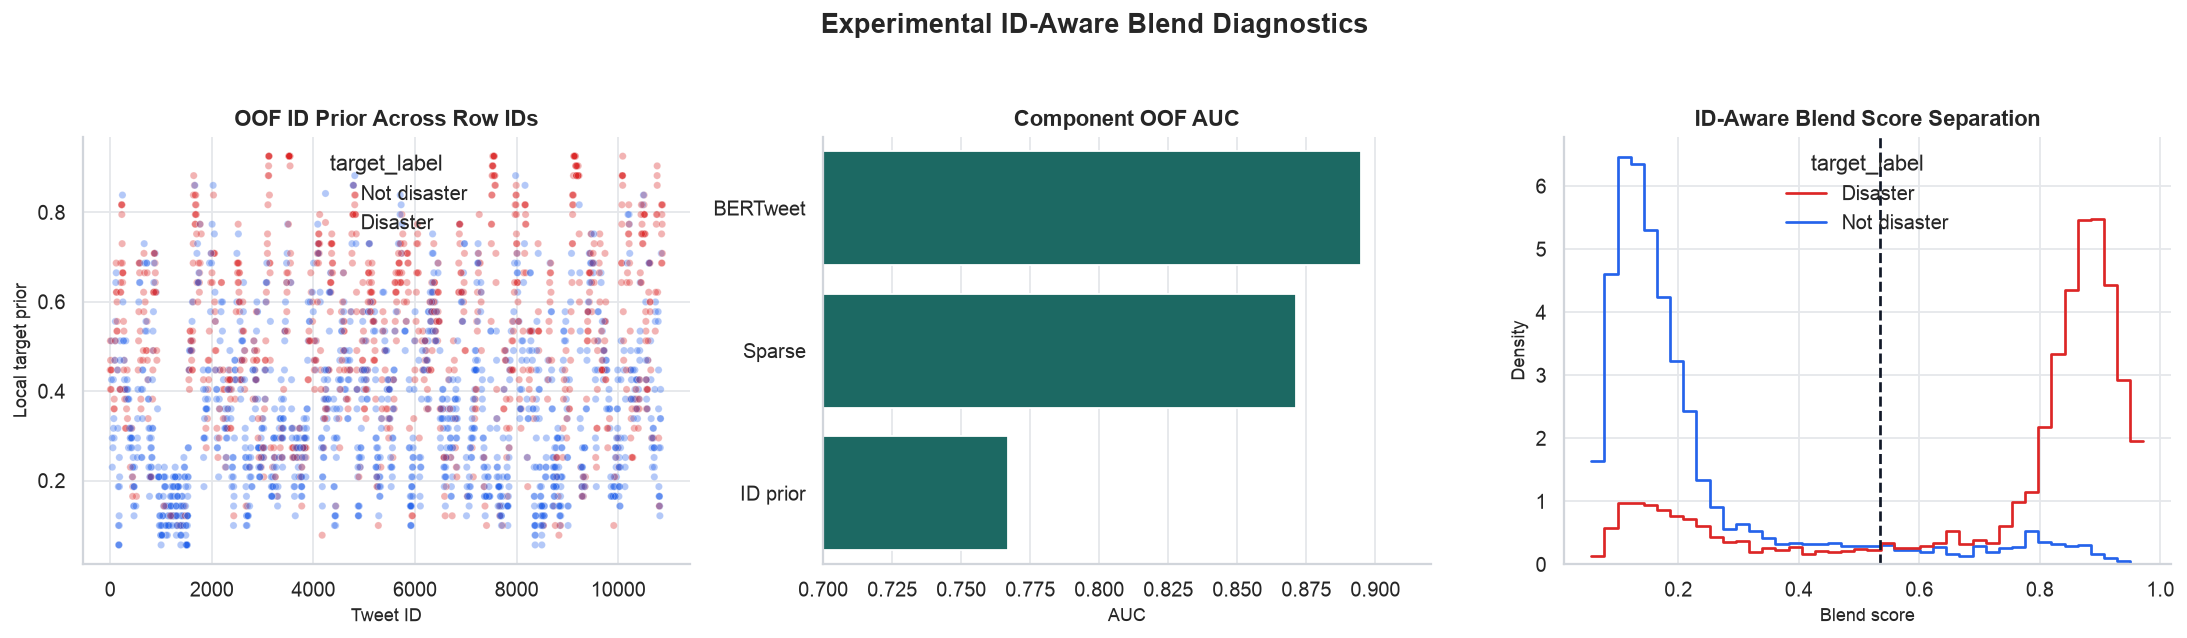

In [12]:
train = pd.read_csv(ROOT / "data/train.csv")
train_labels = train.target.astype(int).to_numpy()
metadata_path = ROOT / "artifacts/id_aware_metadata.json"
prediction_path = ROOT / "artifacts/id_aware_predictions.npz"
bert_path = ROOT / "artifacts/bertweet_ensemble_predictions.npz"
sparse_path = ROOT / "artifacts/sparse_3fold/predictions.npz"

if not prediction_path.exists() or not metadata_path.exists() or not bert_path.exists() or not sparse_path.exists():
    print("No complete ID-aware artifact set found yet. Run upstream models and this experiment first, then rerun diagnostics.")
else:
    metadata = json.loads(metadata_path.read_text())
    predictions = np.load(prediction_path)
    blend_values = predictions["oof_probability"]
    id_prior = predictions["oof_id_prior"]
    bert_values = np.load(bert_path)["oof_probability"]
    sparse_values = np.load(sparse_path)["oof_probability"]

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.7))

    id_frame = pd.DataFrame(
        {
            "row_id": train.id,
            "id_prior": id_prior,
            "target_label": np.where(train_labels == 1, "Disaster", "Not disaster"),
        }
    ).sort_values("row_id")
    sns.scatterplot(
        data=id_frame.sample(min(len(id_frame), 2500), random_state=2027),
        x="row_id",
        y="id_prior",
        hue="target_label",
        alpha=0.35,
        s=16,
        palette={"Not disaster": CLASS_COLORS["Not disaster"], "Disaster": CLASS_COLORS["Disaster"]},
        ax=axes[0],
    )
    axes[0].set_title("OOF ID Prior Across Row IDs")
    axes[0].set_xlabel("Tweet ID")
    axes[0].set_ylabel("Local target prior")

    component_auc = pd.DataFrame(
        {
            "component": ["BERTweet", "Sparse", "ID prior"],
            "auc": [
                roc_auc_score(train_labels, bert_values),
                roc_auc_score(train_labels, sparse_values),
                roc_auc_score(train_labels, id_prior),
            ],
        }
    )
    sns.barplot(data=component_auc, x="auc", y="component", color="#0f766e", ax=axes[1])
    axes[1].set_title("Component OOF AUC")
    axes[1].set_xlabel("AUC")
    axes[1].set_ylabel("")
    axes[1].set_xlim(0.70, 0.92)

    blend_frame = pd.DataFrame(
        {
            "score": blend_values,
            "target_label": np.where(train_labels == 1, "Disaster", "Not disaster"),
        }
    )
    threshold = float(metadata.get("threshold", best_f1(train_labels, blend_values)[1]))
    score = float(metadata.get("oof_f1", best_f1(train_labels, blend_values)[0]))
    sns.histplot(
        data=blend_frame,
        x="score",
        hue="target_label",
        bins=42,
        stat="density",
        common_norm=False,
        element="step",
        fill=False,
        palette={"Not disaster": CLASS_COLORS["Not disaster"], "Disaster": CLASS_COLORS["Disaster"]},
        ax=axes[2],
    )
    axes[2].axvline(threshold, color="#111827", linestyle="--", linewidth=1.5)
    axes[2].set_title("ID-Aware Blend Score Separation")
    axes[2].set_xlabel("Blend score")
    axes[2].set_ylabel("Density")

    fig.suptitle("Experimental ID-Aware Blend Diagnostics", fontsize=15, fontweight="bold", y=1.04)
    plt.tight_layout()
    print(f"ID-aware OOF F1={score:.5f} at threshold={threshold:.3f}; review competition rules before submitting.")

